# 01 — Data Audit

**The question this project asks:** how do you know if your training data's labels
are actually correct, and can you trust an automated QA process to catch the bad ones?

This notebook loads CIFAR-10 (60,000 32x32 images, 10 classes) and the published,
human-verified ground truth from the [`cleanlab/label-errors`](https://github.com/cleanlab/label-errors)
GitHub repo — the companion project to the `cleanlab` confident-learning library,
built from the peer-reviewed paper *"Pervasive Label Errors in Test Sets Destabilize
ML Benchmarks"* (Northcutt et al., 2021). That repo published, for CIFAR-10's test
set, the 275 images their own confident-learning run flagged as candidate label
errors, each independently reviewed by 5 Amazon Mechanical Turk workers who voted on
whether the dataset's given label was correct.

**Why CIFAR-10 instead of a more original/novel dataset?** It's a well-worn
benchmark, but that's exactly the point: it's one of the only datasets where an
independent, peer-reviewed, human-verified answer key already exists for label
errors. A more original dataset would look more novel but this project would have no
way to check whether its own QA pipeline actually works — only to assert that it
does. Verifiability was chosen over novelty; this trade-off is stated again in the
case study.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import data_loading as dl

sns.set_theme(style="whitegrid")
CACHE_DIR = PROJECT_ROOT / "data" / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

## Load CIFAR-10 (train + test, 60,000 images total)

In [2]:
train_ds, test_ds = dl.load_cifar10()
print(f"train: {len(train_ds)} images, test: {len(test_ds)} images")
print(f"classes: {train_ds.classes}")
assert train_ds.classes == dl.CLASS_NAMES

train: 50000 images, test: 10000 images
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Load the published ground truth (`cleanlab/label-errors`, CIFAR-10 test set)

In [3]:
mturk_df, original_labels = dl.load_ground_truth()
print(f"images independently reviewed by 5 MTurk workers: {len(mturk_df)}")
print(f"of those, confirmed label errors (majority disagreed with the given label): "
      f"{mturk_df['confirmed_error'].sum()}")
mturk_df.head()

images independently reviewed by 5 MTurk workers: 275
of those, confirmed label errors (majority disagreed with the given label): 54


,given_original_label,given_original_label_name,our_guessed_label,our_guessed_label_name,mturk_given_votes,mturk_guessed_votes,mturk_neither_votes,mturk_both_votes,confirmed_error
split_index,,,,,,,,,
20,7,horse,5,dog,3,0,0,2,False
52,0,airplane,3,cat,3,1,0,1,False
57,7,horse,3,cat,4,0,0,1,False
58,4,deer,5,dog,5,0,0,0,False
61,3,cat,5,dog,4,1,0,0,False


This matches the number publicly reported for CIFAR-10's test set in the
Northcutt et al. paper and on [labelerrors.com](https://labelerrors.com):
**275 candidate errors reviewed, 54 confirmed** (~0.54% of the 10,000-image test
set). That's a useful integrity check before doing anything else — if this count
didn't match, the ground-truth file would be misread or misaligned.

### Index-alignment sanity check

The `cleanlab/label-errors` `id` field is supposed to be the index into CIFAR-10's
*native* test-set order — the same order `torchvision.datasets.CIFAR10` loads. If
that assumption is wrong, every downstream precision/recall number would be
comparing the wrong images. Check it directly using the repo's own
`cifar10_test_set_original_labels.npy` (independent of torchvision) and cross-check
against torchvision's own labels.

In [4]:
test_labels = np.array(test_ds.targets)

# (a) torchvision's own labels vs. the label-errors repo's original-labels array
mismatch_a = int((test_labels != original_labels).sum())
print(f"torchvision test labels vs. label-errors original_labels.npy: {mismatch_a} mismatches / {len(test_labels)}")

# (b) for every MTurk-reviewed item, does its `given_original_label` match
#     torchvision's label at that same index?
mismatch_b = sum(
    1 for split_idx, row in mturk_df.iterrows()
    if test_labels[split_idx] != row["given_original_label"]
)
print(f"MTurk given_original_label vs. torchvision label at same index: {mismatch_b} mismatches / {len(mturk_df)}")

assert mismatch_a == 0 and mismatch_b == 0, "Index alignment failed -- do not proceed"
print("Index alignment confirmed: ground truth indices line up exactly with torchvision's CIFAR-10 test set order.")

torchvision test labels vs. label-errors original_labels.npy: 0 mismatches / 10000
MTurk given_original_label vs. torchvision label at same index: 0 mismatches / 275
Index alignment confirmed: ground truth indices line up exactly with torchvision's CIFAR-10 test set order.


## Build the master per-image table (60,000 rows: 50,000 train + 10,000 test)

In [5]:
master_df = dl.build_master_dataframe(train_ds, test_ds, mturk_df)
print(master_df.shape)
assert master_df.shape[0] == 60000
assert master_df["gt_reviewed"].sum() == len(mturk_df)
master_df.head()

(60000, 10)


,global_id,split,split_index,true_label,true_label_name,gt_reviewed,gt_confirmed_error,gt_mturk_given_votes,gt_guessed_label,gt_guessed_label_name
0,0,train,0,6,frog,False,<NA>,<NA>,<NA>,<NA>
1,1,train,1,9,truck,False,<NA>,<NA>,<NA>,<NA>
2,2,train,2,9,truck,False,<NA>,<NA>,<NA>,<NA>
3,3,train,3,4,deer,False,<NA>,<NA>,<NA>,<NA>
4,4,train,4,1,automobile,False,<NA>,<NA>,<NA>,<NA>


## Class distribution — train vs. test

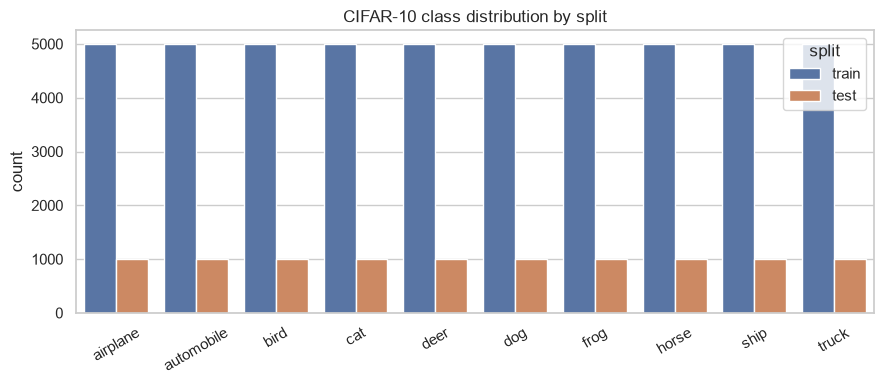

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.countplot(data=master_df, x="true_label_name", hue="split", order=dl.CLASS_NAMES, ax=ax)
ax.set_title("CIFAR-10 class distribution by split")
ax.set_xlabel("")
ax.set_ylabel("count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "01_class_distribution.png", dpi=150)
plt.show()

CIFAR-10 is perfectly class-balanced by design (6,000 train + 1,000 test images per
class), so this is mostly a "did the loader work" check rather than a real finding
— any deviation from a flat distribution here would mean something went wrong
upstream.

## Where do the *known* errors concentrate? (ground truth only, no model yet)

In [7]:
reviewed = master_df[master_df["gt_reviewed"]].copy()
reviewed["gt_confirmed_error"] = reviewed["gt_confirmed_error"].astype(bool)

by_class = (
    reviewed.groupby("true_label_name")
    .agg(reviewed_count=("gt_confirmed_error", "size"), confirmed_errors=("gt_confirmed_error", "sum"))
    .reindex(dl.CLASS_NAMES)
)
by_class["confirmed_error_rate_of_reviewed"] = by_class["confirmed_errors"] / by_class["reviewed_count"]
by_class

,reviewed_count,confirmed_errors,confirmed_error_rate_of_reviewed
true_label_name,,,
airplane,27,6,0.222222
automobile,20,7,0.350000
bird,34,4,0.117647
cat,59,17,0.288136
deer,18,7,0.388889
dog,38,3,0.078947
frog,20,1,0.050000
horse,16,3,0.187500
ship,11,2,0.181818


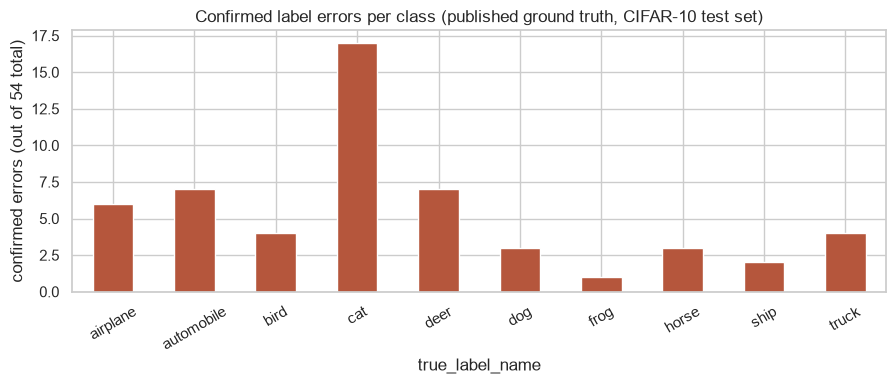

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
by_class["confirmed_errors"].plot(kind="bar", ax=ax, color="#b5563c")
ax.set_title("Confirmed label errors per class (published ground truth, CIFAR-10 test set)")
ax.set_ylabel("confirmed errors (out of 54 total)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "01_confirmed_errors_by_class.png", dpi=150)
plt.show()

This is the *ground truth's own* answer to "where do label errors concentrate" —
independent of any model this project builds. It's worth looking at before running
confident learning, so notebook 04's "does our QA process find the same pattern"
comparison isn't circular.

## A look at a few confirmed errors

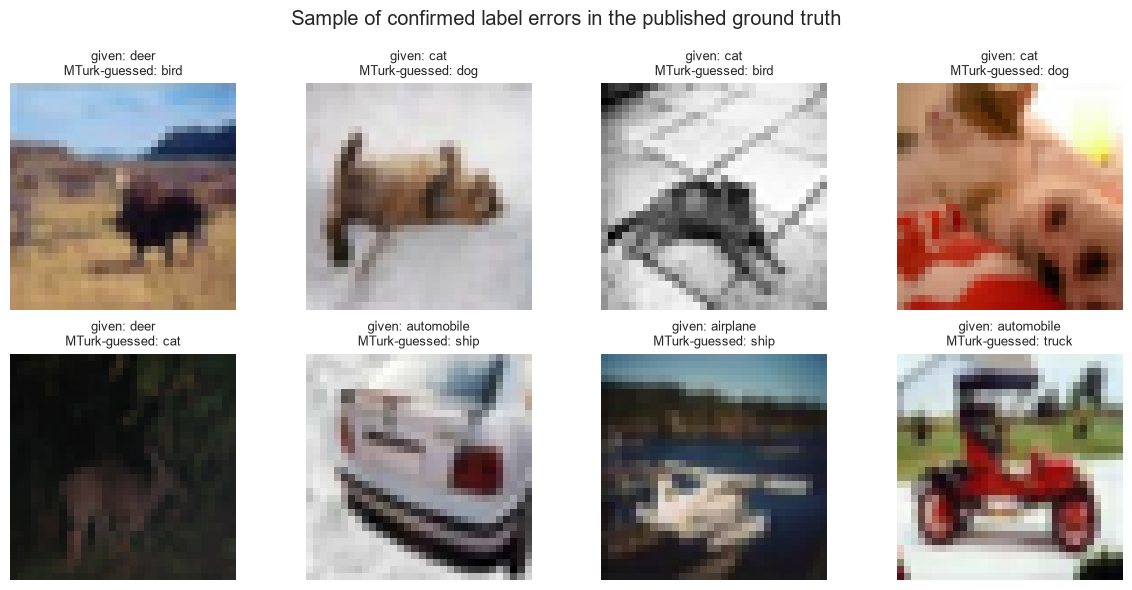

In [9]:
confirmed = reviewed[reviewed["gt_confirmed_error"]].sort_values("split_index").head(8)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (_, row) in zip(axes.flat, confirmed.iterrows()):
    img = dl.get_image_array(test_ds, int(row["split_index"]))
    ax.imshow(img)
    ax.set_title(f"given: {row['true_label_name']}\nMTurk-guessed: {row['gt_guessed_label_name']}", fontsize=9)
    ax.axis("off")
plt.suptitle("Sample of confirmed label errors in the published ground truth")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "01_confirmed_error_examples.png", dpi=150)
plt.show()

## Cache the master table for the next notebook

In [10]:
master_df.to_parquet(CACHE_DIR / "master_df.parquet")
print("saved:", CACHE_DIR / "master_df.parquet")

saved: C:\Users\User\Desktop\LABEL-QUALITY-ANALYZER\data\cache\master_df.parquet


## Handoff to notebook 02

Everything above is ground truth and raw data — no model yet. Next: extract frozen
embeddings from a pretrained ImageNet CNN and train a cross-validated classifier on
them, which produces the out-of-fold predicted probabilities confident learning
needs.